In [85]:
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt

**Printing the dataset**

In [86]:
df = sns.load_dataset("taxis")
print(df.head())

               pickup             dropoff  passengers  distance  fare   tip  \
0 2019-03-23 20:21:09 2019-03-23 20:27:24           1      1.60   7.0  2.15   
1 2019-03-04 16:11:55 2019-03-04 16:19:00           1      0.79   5.0  0.00   
2 2019-03-27 17:53:01 2019-03-27 18:00:25           1      1.37   7.5  2.36   
3 2019-03-10 01:23:59 2019-03-10 01:49:51           1      7.70  27.0  6.15   
4 2019-03-30 13:27:42 2019-03-30 13:37:14           3      2.16   9.0  1.10   

   tolls  total   color      payment            pickup_zone  \
0    0.0  12.95  yellow  credit card        Lenox Hill West   
1    0.0   9.30  yellow         cash  Upper West Side South   
2    0.0  14.16  yellow  credit card          Alphabet City   
3    0.0  36.95  yellow  credit card              Hudson Sq   
4    0.0  13.40  yellow  credit card           Midtown East   

            dropoff_zone pickup_borough dropoff_borough  
0    UN/Turtle Bay South      Manhattan       Manhattan  
1  Upper West Side South      

**Checking the dataset for missing values in the columns
and here**

* payment =     44
* pickup_zone =    26
* dropoff_zone =   45
* pickup_borough =  26
* dropoff_borough = 45

missing values are there.




In [87]:
print(df.isnull().sum())

pickup              0
dropoff             0
passengers          0
distance            0
fare                0
tip                 0
tolls               0
total               0
color               0
payment            44
pickup_zone        26
dropoff_zone       45
pickup_borough     26
dropoff_borough    45
dtype: int64


checking the type of the data

In [88]:
print(df.dtypes)


pickup             datetime64[ns]
dropoff            datetime64[ns]
passengers                  int64
distance                  float64
fare                      float64
tip                       float64
tolls                     float64
total                     float64
color                      object
payment                    object
pickup_zone                object
dropoff_zone               object
pickup_borough             object
dropoff_borough            object
dtype: object


**Finding the most frequently occurring values in the columns containing missing values to help handle missing data using the mode imputation method**
* .mode()= to find the most frequently occurring value in each column
* iloc[0]= to take the 1st row of the result

In [89]:
print(df[["payment","pickup_zone","dropoff_zone","pickup_borough","dropoff_borough"]].mode().iloc[0])


payment                      credit card
pickup_zone               Midtown Center
dropoff_zone       Upper East Side North
pickup_borough                 Manhattan
dropoff_borough                Manhattan
Name: 0, dtype: object


**Handling missing values**

* df["payment"]= storing the updated values into the payment column.
* fillna (df["payment"].mode()[0]= fill the missing value places with the mode of the values .
* Then checking is there is any missing values .

In [90]:
df["payment"] = df["payment"].fillna(df["payment"].mode()[0])
print(df["payment"].isnull().sum())


0


**handeling missing values **

* removing all the missing rows in
  * pickup _zone
  * dropoff_zone
  * pickup_borough
  * dropoff_borough

 Here we cant just replace the missing spot with the mode value .

* They are locations so that will be error so we are removing the entire row.  

In [91]:
df = df.dropna(subset=["pickup_zone"])
print(df["pickup_zone"].isnull().sum())

0


In [92]:
df = df.dropna(subset=["dropoff_zone"])
print(df["dropoff_zone"].isnull().sum())

0


In [93]:
df = df.dropna(subset=["pickup_borough"])
print(df["pickup_borough"].isnull().sum())

0


In [94]:
df = df.dropna(subset=["dropoff_borough"])
print(df["dropoff_borough"].isnull().sum())

0


**Checking for any missing values in the dataset**
  * All the missing values have been handled

In [95]:
print(df.isnull().sum())

pickup             0
dropoff            0
passengers         0
distance           0
fare               0
tip                0
tolls              0
total              0
color              0
payment            0
pickup_zone        0
dropoff_zone       0
pickup_borough     0
dropoff_borough    0
dtype: int64


**Line Chart**

**Plot a line chart to visualize the fare over time, using the pickup timestamp as the x-axis and fare as the y-axis. Ensure the pickup column is converted to a datetime format before plotting.**

* We sort the dataset to avoid the line from moving back and forth.
* plt.figure(figsize=(10, 5))= setting the size of the figure.
* plt.plot(df["pickup"], df["fare"], color="purple")= creating line graph with   
   * x axis= pickup time
   * y axis= fare
   * color purple
   * title=fare over time

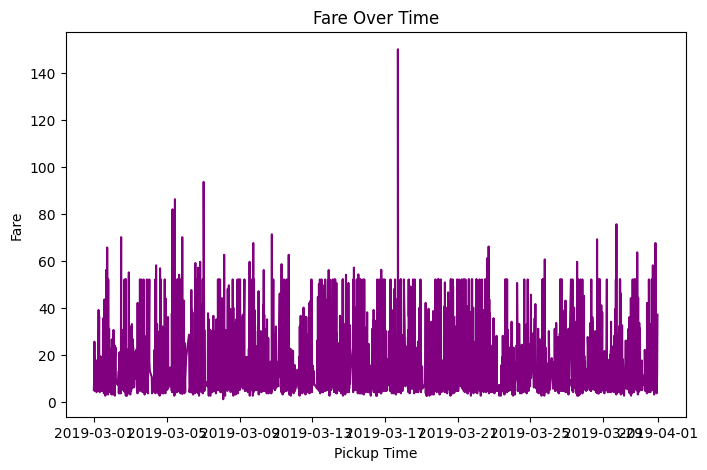

In [96]:
df = df.sort_values("pickup")


plt.figure(figsize=(8, 5))
plt.plot(df["pickup"], df["fare"], color="purple")

plt.xlabel("Pickup Time")
plt.ylabel("Fare")
plt.title("Fare Over Time")
plt.show()


In [97]:
borough_fare = df.groupby("pickup_borough")["fare"].sum()
print(borough_fare)

pickup_borough
Bronx         2078.91
Brooklyn      6227.48
Manhattan    58323.92
Queens       15541.06
Name: fare, dtype: float64


**Bar Chart**

**Create a bar chart to show the total fare for each pickup_borough. Group the data by pickup_borough and sum the fare for each group.**

* Creating a bar graph
   * x = borough
   * y = total fare
   * title = total fare by borough  

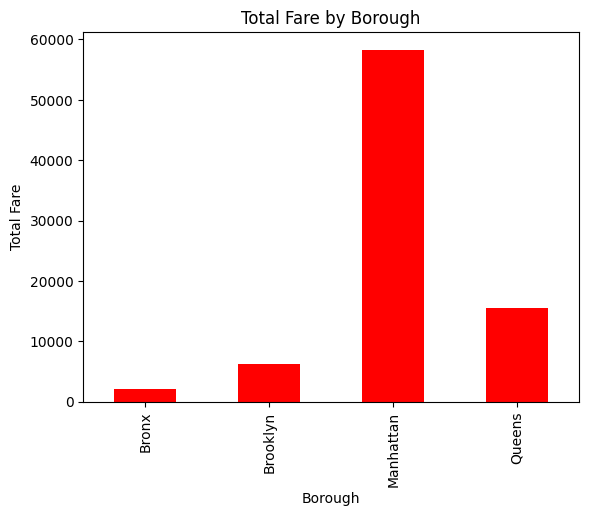

In [98]:
borough_fare.plot(kind="bar", color="red")
plt.xlabel("Borough")
plt.ylabel("Total Fare")
plt.title("Total Fare by Borough")
plt.show()

**Here we are getting the count for both credit card and cash from payment column**

* To just get the correct proportion to make the analysis bit easy .**

In [99]:
payment_counts = df["payment"].value_counts()
print(payment_counts)

payment
credit card    4588
cash           1795
Name: count, dtype: int64


**Pie Chart**

**Plot a pie chart showing the distribution of trips based on the payment method (creditcard, cash, etc.). Each slice should represent the count of trips for a specific payment method.**

creating the pie chart and using colormap because we use more than 1 color

* With title distribution of taxi trips by payment method


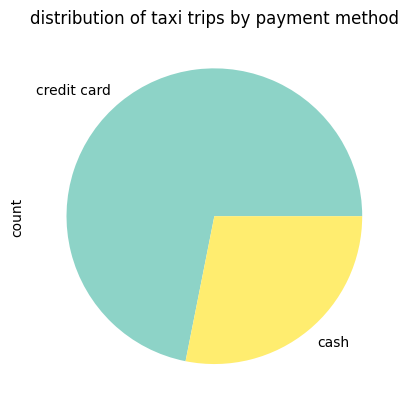

In [100]:
payment_counts.plot(kind="pie", colormap="Set3")
plt.title("distribution of taxi trips by payment method")
plt.show()

**Histogram**

**Create a histogram to visualize the distribution of distance. Customize the number of bins for better granularity and ensure the plot is easy to interpret.**
 * here we are creating a histogram with
    * distance in 10 intervel
    * x axis= distance
    * y axis= frequency
    * title distribution of taxi trip distance
    * color green

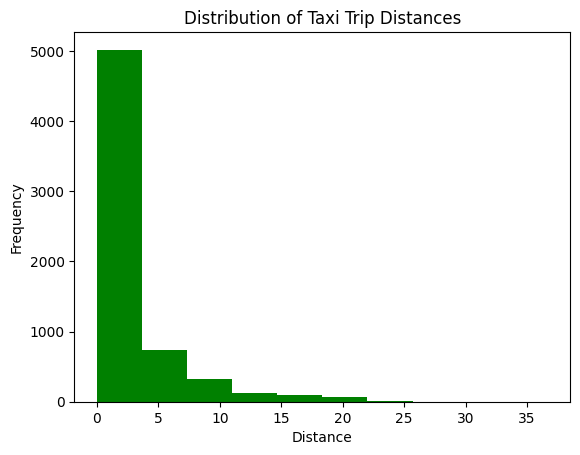

In [101]:
plt.hist(df["distance"], bins=10, color="green")
plt.xlabel("Distance")
plt.ylabel("Frequency")
plt.title("Distribution of Taxi Trip Distances")
plt.show()

**Box Plot**

**Plot a box plot to visualize the distribution of tip amounts for each pickup_borough.Use pickup_borough as the categorical axis and tip as the numeric axis.**
 * Creates a box plot of tip amounts grouped by pickup borough.
     * with x axis=pickup borough
     * y axis=tip amount
     * title tip distribution by pickup borough
* plt.suptitle("")= to remove the title added by panda.    

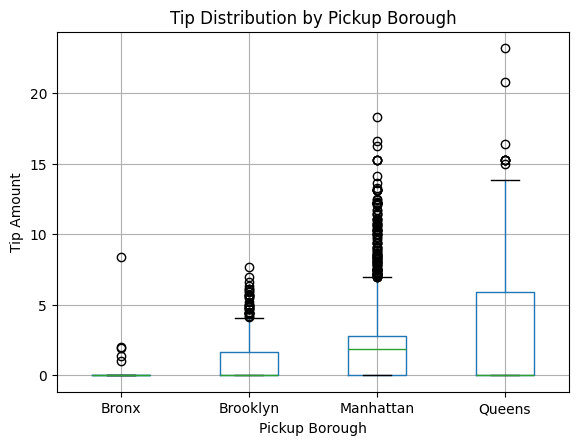

In [102]:

df.boxplot(column="tip", by="pickup_borough")

plt.xlabel("Pickup Borough")
plt.ylabel("Tip Amount")
plt.title("Tip Distribution by Pickup Borough")
plt.suptitle("")
plt.show()


**Count Plot**

**Create a count plot to visualize the number of trips in each pickup_borough. The x-axis should represent the boroughs, and the y-axis should show the count of trips.**

* this is using Seaborn library
* x axis = pickup_borough
* plt.grid(true)= to get grid in the graph

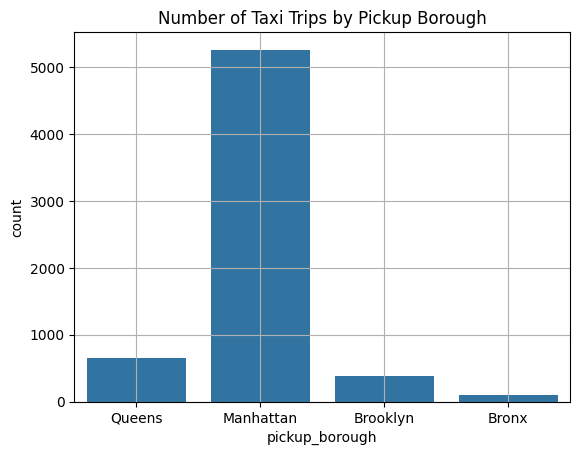

In [103]:
sns.countplot(data=df, x="pickup_borough")
plt.title("Number of Taxi Trips by Pickup Borough")
plt.grid(True)
plt.show()


**Scatter Plot**

**Plot a scatter plot to show the relationship between distance and fare. Use
distance on the x-axis and fare on the y-axis to visualize any correlation. Color the points based on the pickup_borough to differentiate the trips by their respective boroughs.**

* Creating a scatter graph
    * x axis = distance
    * y axis = fare
    * hue = to get different colors for each pickup_borough

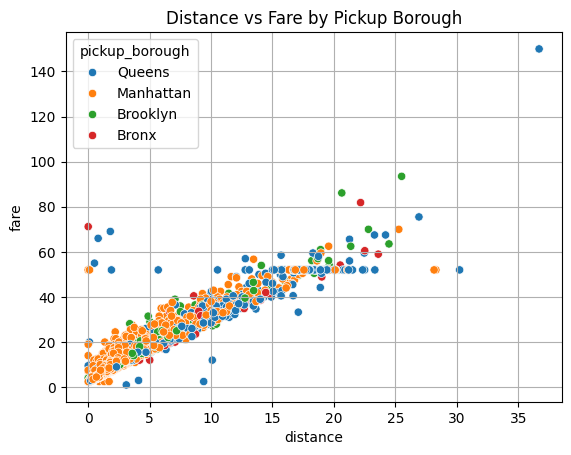

In [104]:
sns.scatterplot(data=df, x="distance", y="fare", hue="pickup_borough")
plt.title("Distance vs Fare by Pickup Borough")
plt.grid(True)
plt.show()

**Heatmap**

**Plot a heatmap to visualize the correlation between numerical variables such as distance, fare, tip, tolls, and total. Use a correlation matrix to highlight the
relationships.**

* columns taken for analysis are

       * distance
       * fare
       * tip
       * tolls
       * total
 * corr = is the variable introduced to store the correlation matrix.
 * sns.heatmap() = to displays the correlation matrix as a color-coded grid.      
 * annot=true =to display the values inside the colored grid
 * cmap="coolwarm"  = to get the color palate for correlation heatmap

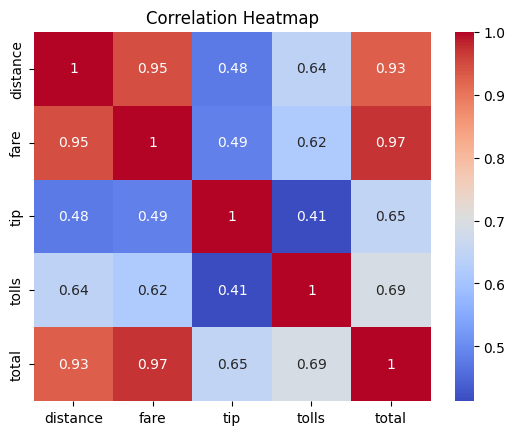

In [105]:
corr = df[["distance", "fare", "tip", "tolls", "total"]].corr()

sns.heatmap(corr, annot=True, cmap="coolwarm")

plt.title("Correlation Heatmap")
plt.show()

**Pair Plot**

**Create a pair plot to visualize the pairwise relationships between distance, fare, tip, and total. Color the data points according to the pickup_zone method to compare how different zones affect these variables.**

* data=df = specifying the dataframe.
* vars=["distance","fare","tip","total"]

these are the columns we take to compare the numerical value.




In [ ]:
sns.pairplot(
    data=df,
    vars=["distance", "fare", "tip", "total"],
    hue="pickup_zone"
)
plt.show()

**Violin Plot**

**Plot a violin plot to show the distribution of fare for each payment method. Use the
payment method as the categorical axis and fare as the numeric axis to visualize its
distribution.**

* creating a violin plot

      * x axis = payment method
      * y axis = fare amount
      * title = fare distribution by payment method
      * plt.grid(true)= getting grid  


In [ ]:
sns.violinplot(data=df, x="payment", y="fare")

plt.title("Fare Distribution by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Fare Amount")
plt.grid(True)
plt.show()